# AI-Powered Student Performance Prediction System

## Project Overview

This project aims to analyze student marks, visualize academic performance, and use machine learning to predict student performance. It will be developed step by step using Python, data analysis, and machine learning techniques.

## 1. Import Libraries

In this project, I will use Pandas for data analysis, NumPy for numerical operations, and Matplotlib for data visualization.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Create the Student Dataset

In this section, I will create a sample dataset containing student names and marks. This dataset will be used to analyze student performance.

In [8]:
data = {
    "Name": ["Aman", "Priya", "Rahul", "Neha", "Simran"],
    "Marks": [80, 92, 67, 45, 88]
}

df = pd.DataFrame(data)

print(df)

     Name  Marks
0    Aman     80
1   Priya     92
2   Rahul     67
3    Neha     45
4  Simran     88


## 3. Analyze Student Performance

In this section, I will use Pandas to calculate summary statistics and identify the highest and lowest marks in the dataset.

In [9]:
print("Average Marks : ", df["Marks"].mean())
print("Highest Marks : ",df["Marks"].max())
print("Lowest Marks :  ",df["Marks"].min())

Average Marks :  74.4
Highest Marks :  92
Lowest Marks :   45


## 4. Data Visualization

In this section, I will create a bar chart using Matplotlib to compare the marks obtained by different students.

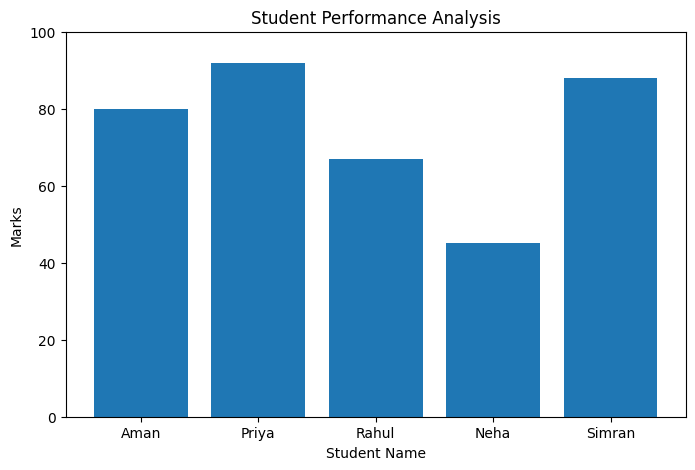

In [10]:
plt.figure(figsize = (8,5))

plt.bar(df["Name"],df["Marks"])
plt.title("Student Performance Analysis")
plt.xlabel("Student Name")
plt.ylabel("Marks")

plt.ylim(0,100)
plt.show()

## 5. Identify the Top-Performing Student

In this section, I will identify the student with the highest marks using Pandas. This helps summarize student performance automatically.

In [11]:
top_student = df.loc[df["Marks"].idxmax()]
print("Top Performing Student : ", top_student["Name"])
print("Highest Marks : ", top_student["Marks"])

Top Performing Student :  Priya
Highest Marks :  92


## 6. Classify Student Performance

In this section, I will classify students into performance categories based on their marks. This will help summarize academic performance and identify students who may need additional support.

In [12]:
def classify_performance(marks):
    if marks >= 85:
        return "Excellent"
    elif marks >= 70:
        return "Good"
    elif marks >= 50:
        return "Average"
    else:
        return "Needs Improvement"

df["Performance"] = df["Marks"].apply(classify_performance)

print(df)

     Name  Marks        Performance
0    Aman     80               Good
1   Priya     92          Excellent
2   Rahul     67            Average
3    Neha     45  Needs Improvement
4  Simran     88          Excellent


## 7. Performance Category Summary

In this section, I will count the number of students in each performance category to understand the overall distribution of student performance.

In [13]:
performance_summary = df["Performance"].value_counts()
print(performance_summary)

Performance
Excellent            2
Good                 1
Average              1
Needs Improvement    1
Name: count, dtype: int64


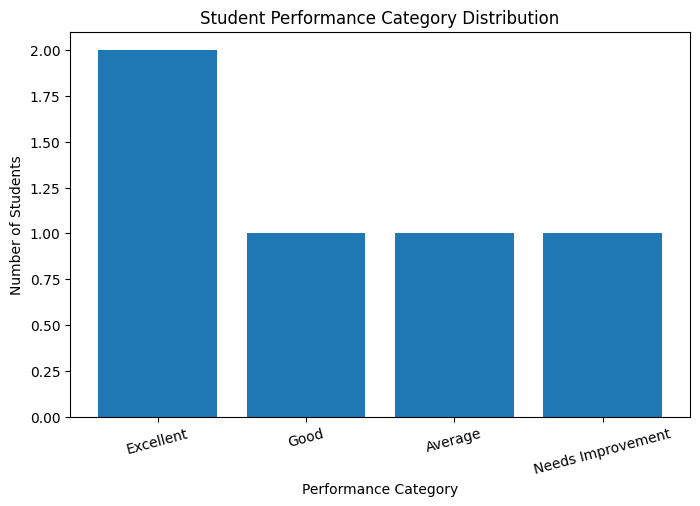

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(performance_summary.index, performance_summary.values)

plt.title("Student Performance Category Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

plt.xticks(rotation=15)
plt.show()

## 8. Expanding the Student Dataset

In this section, I will add study hours, attendance percentage, and previous assessment scores to explore how different factors relate to student performance.

In [15]:
student_data = {
    "Name": ["Aman", "Priya", "Rahul", "Neha", "Simran"],
    "Study_Hours": [2, 5, 3, 1, 4],
    "Attendance": [85, 96, 75, 60, 92],
    "Previous_Score": [75, 90, 65, 40, 82],
    "Final_Marks": [80, 92, 67, 45, 88]
}

student_df = pd.DataFrame(student_data)

print(student_df)

     Name  Study_Hours  Attendance  Previous_Score  Final_Marks
0    Aman            2          85              75           80
1   Priya            5          96              90           92
2   Rahul            3          75              65           67
3    Neha            1          60              40           45
4  Simran            4          92              82           88


## 9. Study Hours vs Final Marks

In this section, I will compare students' daily study hours with their final marks to explore whether a relationship exists between the two variables.

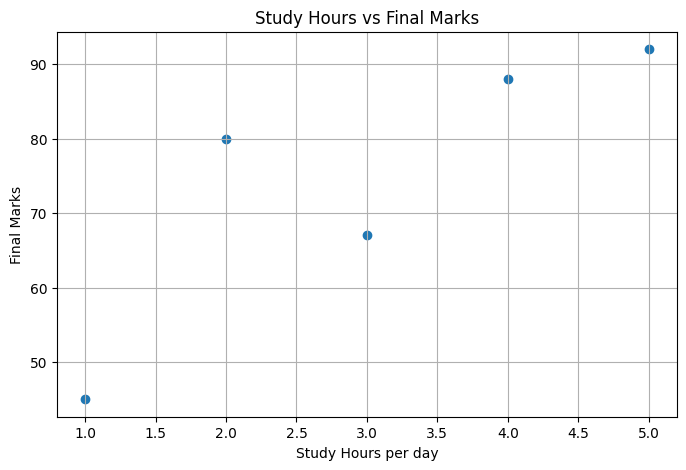

In [16]:
plt.figure(figsize = (8,5))

plt.scatter(student_df["Study_Hours"],student_df["Final_Marks"])
plt.xlabel("Study Hours per day")
plt.ylabel("Final Marks")
plt.title("Study Hours vs Final Marks")

plt.grid(True)
plt.show()

## 10. Attendance vs Final Marks

In this section, I will visualize the relationship between students' attendance percentages and their final marks to explore whether attendance is associated with academic performance.

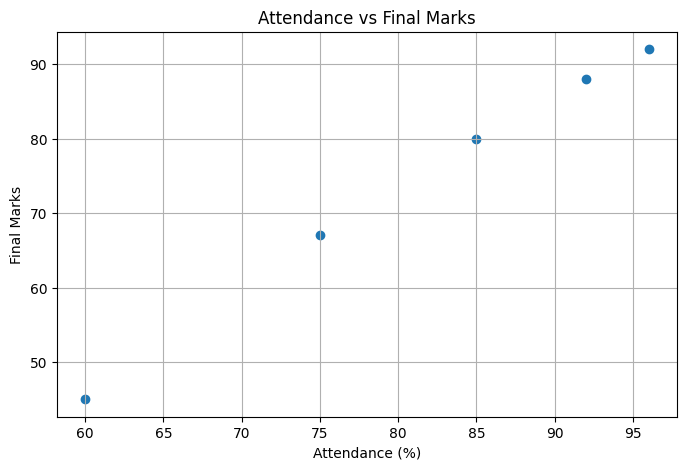

In [17]:
plt.figure(figsize = (8,5))

plt.scatter(student_df["Attendance"],student_df["Final_Marks"])

plt.title("Attendance vs Final Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Final Marks")

plt.grid(True)
plt.show()

## 11. Correlation Analysis

In this section, I will calculate the correlation between attendance, study hours, previous scores, and final marks to explore relationships among student performance factors.

In [18]:
correlation = student_df[
    ["Attendance","Study_Hours","Previous_Score","Final_Marks"]
].corr()
print(correlation)

                Attendance  Study_Hours  Previous_Score  Final_Marks
Attendance        1.000000     0.863401        0.993487     0.998032
Study_Hours       0.863401     1.000000        0.875638     0.848469
Previous_Score    0.993487     0.875638        1.000000     0.995368
Final_Marks       0.998032     0.848469        0.995368     1.000000


## 12. Correlation Heatmap

In this section, I will create a heatmap to visualize the correlations between study hours, attendance, previous scores, and final marks.

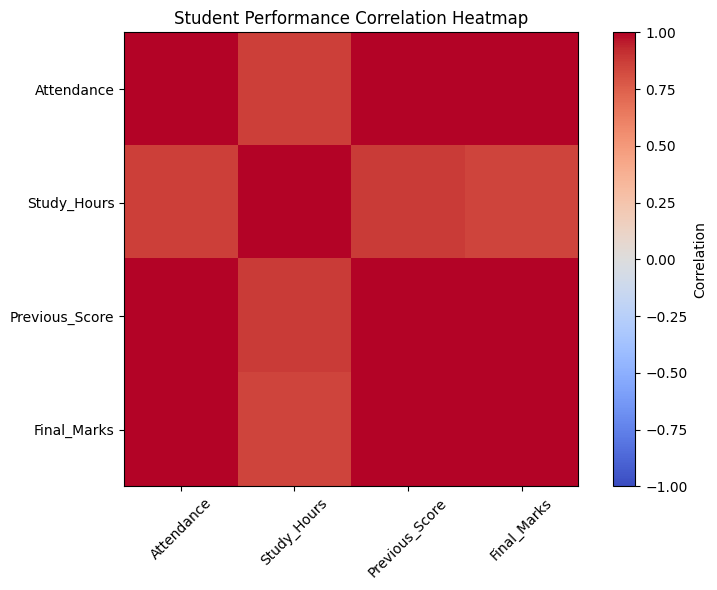

In [19]:
plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Student Performance Correlation Heatmap")
plt.tight_layout()
plt.show()

In [15]:
print(correlation["Final_Marks"].sort_values(ascending=False))

Final_Marks       1.000000
Attendance        0.998032
Previous_Score    0.995368
Study_Hours       0.848469
Name: Final_Marks, dtype: float64


## 13. Preparing Data for Machine Learning

In this section, I will separate the input features from the target variable to prepare the dataset for a machine learning model.

In [20]:
X = student_df[["Study_Hours","Attendance","Previous_Score"]]

Y = student_df["Final_Marks"]

print("Input Variables(X) : ")
print(X)

print("\nTarget Variable(Y) : ")
print(Y)

Input Variables(X) : 
   Study_Hours  Attendance  Previous_Score
0            2          85              75
1            5          96              90
2            3          75              65
3            1          60              40
4            4          92              82

Target Variable(Y) : 
0    80
1    92
2    67
3    45
4    88
Name: Final_Marks, dtype: int64


## 14. Splitting Data into Training and Testing Sets

In this section, I will split the dataset into training and testing sets using Scikit-learn. This prepares the data for training and evaluating a machine learning model.

In [21]:
from sklearn.model_selection import train_test_split

X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2, random_state=42)

print("Training Input Data Shape : ", X_train.shape)
print("Testing Input Data Shape : ", X_test.shape)

print("Training Target Data Shape : ", Y_train.shape)
print("Testing Target Data Shape : ", Y_test.shape)

Training Input Data Shape :  (4, 3)
Testing Input Data Shape :  (1, 3)
Training Target Data Shape :  (4,)
Testing Target Data Shape :  (1,)


## 15. Training a Linear Regression Model

In this section, I will train a Linear Regression model using study hours, attendance, and previous scores to predict final marks.

In [23]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train,Y_train)

print("Model Trained Successfully")

Model Trained Successfully


## 16. Predicting Final Marks

In this section, I will use the trained Linear Regression model to predict final marks from the input features.

In [24]:
predictions = model.predict(X_test)

print("Actual Final Marks : ")
print(Y_test.values)

print("\nPredicted Final Marks :")
print(predictions)

Actual Final Marks : 
[92]

Predicted Final Marks :
[94.2]


## 17. Evaluating the Machine Learning Model

In this section, I will evaluate the Linear Regression model using Mean Absolute Error (MAE) to measure the difference between predicted and actual final marks.

In [25]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(Y_test,predictions)
print("Mean Absolute Error : ", mae)

Mean Absolute Error :  2.200000000000003


In [26]:
comparison = pd.DataFrame({
    "Actual Marks": Y_test.values,
    "Predicted Marks": predictions
})

comparison["Absolute Error"] = abs(
    comparison["Actual Marks"] - comparison["Predicted Marks"]
)

print(comparison.round(2))

   Actual Marks  Predicted Marks  Absolute Error
0            92             94.2             2.2


## 18. Predicting Marks for a New Student

In this section, I will enter a new student's study hours, attendance, and previous score to estimate their final marks using the trained Linear Regression model.

In [27]:
new_student = pd.DataFrame({
    "Study_Hours": [4],
    "Attendance": [90],
    "Previous_Score": [85]
})

predicted_marks = model.predict(new_student)

print("New Student Details:")
print(new_student)

print("\nPredicted Final Marks:", round(predicted_marks[0], 2))

New Student Details:
   Study_Hours  Attendance  Previous_Score
0            4          90              85

Predicted Final Marks: 87.44


## 19. Student Performance Report

In this section, I will create a consolidated report showing each student's study hours, attendance, previous score, final marks, and performance category.

In [28]:
student_df["Performance"] = student_df["Final_Marks"].apply(
    classify_performance
)

student_report = student_df.sort_values(
    by="Final_Marks",
    ascending=False
)

print(student_report.to_string(index=False))

  Name  Study_Hours  Attendance  Previous_Score  Final_Marks       Performance
 Priya            5          96              90           92         Excellent
Simran            4          92              82           88         Excellent
  Aman            2          85              75           80              Good
 Rahul            3          75              65           67           Average
  Neha            1          60              40           45 Needs Improvement


## 20. Exporting the Student Report

In this section, I will export the student performance report to a CSV file so it can be opened in Excel or used by other data analysis tools.

In [29]:
student_report.to_csv(
    "student_performance_report.csv",
    index=False
)

print("Student report exported successfully!")

Student report exported successfully!


## 21. Creating a Student Performance Prediction Function

In this section, I will create a reusable Python function that accepts study hours, attendance, and previous scores and returns the predicted final marks.

In [30]:
def predict_student_marks(study_hours, attendance, previous_score):
    new_student = pd.DataFrame({
        "Study_Hours": [study_hours],
        "Attendance": [attendance],
        "Previous_Score": [previous_score]
    })

    predicted_marks = model.predict(new_student)

    return round(predicted_marks[0], 2)


result = predict_student_marks(4, 90, 85)

print("Predicted Final Marks:", result)

Predicted Final Marks: 87.44


## 22. Input Validation for Student Predictions

In this section, I will validate study hours, attendance, and previous scores before making predictions to prevent invalid inputs.

In [31]:
def predict_student_marks(study_hours, attendance, previous_score):
    if study_hours < 0:
        return "Error: Study hours cannot be negative."

    if not 0 <= attendance <= 100:
        return "Error: Attendance must be between 0 and 100."

    if not 0 <= previous_score <= 100:
        return "Error: Previous score must be between 0 and 100."

    new_student = pd.DataFrame({
        "Study_Hours": [study_hours],
        "Attendance": [attendance],
        "Previous_Score": [previous_score]
    })

    predicted_marks = model.predict(new_student)

    return round(predicted_marks[0], 2)


print(predict_student_marks(4, 90, 85))
print(predict_student_marks(4, 120, 85))

87.44
Error: Attendance must be between 0 and 100.


## 23. Interactive Student Performance Prediction

In this section, I will allow users to enter study hours, attendance, and previous scores through the console and receive a predicted final mark.

In [32]:
try:
    study_hours = float(input("Enter study hours per day: "))
    attendance = float(input("Enter attendance percentage: "))
    previous_score = float(input("Enter previous score: "))

    result = predict_student_marks(
        study_hours,
        attendance,
        previous_score
    )

    print("\nPrediction Result:", result)

except ValueError:
    print("Error: Please enter valid numbers.")

Enter study hours per day: 4
Enter attendance percentage: 95
Enter previous score: 85

Prediction Result: 91.78


## 24. Classifying Predicted Student Performance

In this section, I will classify predicted final marks into performance categories such as Excellent, Good, Average, and Needs Improvement.

In [33]:
def classify_performance(marks):
    if marks >= 85:
        return "Excellent"
    elif marks >= 70:
        return "Good"
    elif marks >= 50:
        return "Average"
    else:
        return "Needs Improvement"


result = predict_student_marks(4, 90, 85)

if isinstance(result, (int, float)):
    category = classify_performance(result)

    print("Predicted Final Marks:", result)
    print("Performance Category:", category)
else:
    print(result)

Predicted Final Marks: 87.44
Performance Category: Excellent


## 25. Complete Student Prediction Report

In this section, I will combine input validation, mark prediction, and performance classification to generate a complete report for a student.

In [34]:
def generate_student_report(study_hours, attendance, previous_score):
    predicted_marks = predict_student_marks(
        study_hours,
        attendance,
        previous_score
    )

    if not isinstance(predicted_marks, (int, float)):
        print(predicted_marks)
        return

    category = classify_performance(predicted_marks)

    print("\n--- STUDENT PERFORMANCE REPORT ---")
    print("Study Hours:", study_hours)
    print("Attendance:", attendance, "%")
    print("Previous Score:", previous_score)
    print("Predicted Final Marks:", predicted_marks)
    print("Performance Category:", category)


generate_student_report(4, 90, 85)


--- STUDENT PERFORMANCE REPORT ---
Study Hours: 4
Attendance: 90 %
Previous Score: 85
Predicted Final Marks: 87.44
Performance Category: Excellent


## 26. Dataset Quality Check

In this section, I will inspect the dataset size, column data types, and missing values before improving the machine learning model.

In [35]:
print("Dataset Shape:")
print(student_df.shape)

print("\nColumn Data Types:")
print(student_df.dtypes)

print("\nMissing Values:")
print(student_df.isnull().sum())

print("\nDuplicate Rows:")
print(student_df.duplicated().sum())

Dataset Shape:
(5, 6)

Column Data Types:
Name              object
Study_Hours        int64
Attendance         int64
Previous_Score     int64
Final_Marks        int64
Performance       object
dtype: object

Missing Values:
Name              0
Study_Hours       0
Attendance        0
Previous_Score    0
Final_Marks       0
Performance       0
dtype: int64

Duplicate Rows:
0


## 27. Creating a Larger Simulated Student Dataset

In this section, I will generate 100 simulated student records containing study hours, attendance, previous scores, and final marks to practise data analysis and machine learning.

In [36]:
np.random.seed(42)

number_of_students = 100

study_hours = np.random.uniform(1, 6, number_of_students)
attendance = np.random.uniform(50, 100, number_of_students)
previous_score = np.random.uniform(35, 95, number_of_students)

noise = np.random.normal(0, 5, number_of_students)

final_marks = (
    5 * study_hours
    + 0.3 * attendance
    + 0.4 * previous_score
    + noise
)

final_marks = np.clip(final_marks, 0, 100)

large_student_df = pd.DataFrame({
    "Study_Hours": study_hours.round(1),
    "Attendance": attendance.round(1),
    "Previous_Score": previous_score.round(1),
    "Final_Marks": final_marks.round(1)
})

print(large_student_df.head())
print("\nDataset shape:", large_student_df.shape)

   Study_Hours  Attendance  Previous_Score  Final_Marks
0          2.9        51.6            73.5         59.5
1          5.8        81.8            40.0         66.1
2          4.7        65.7            44.7         71.6
3          4.0        75.4            88.9         81.3
4          1.8        95.4            71.4         55.9

Dataset shape: (100, 4)


## 28. Exploratory Data Analysis on the Larger Dataset

In this section, I will examine summary statistics, missing values, and the distribution of final marks in the larger simulated dataset.

In [37]:
print("Dataset Information:")
print(large_student_df.info())

print("\nSummary Statistics:")
print(large_student_df.describe())

print("\nMissing Values:")
print(large_student_df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Study_Hours     100 non-null    float64
 1   Attendance      100 non-null    float64
 2   Previous_Score  100 non-null    float64
 3   Final_Marks     100 non-null    float64
dtypes: float64(4)
memory usage: 3.3 KB
None

Summary Statistics:
       Study_Hours  Attendance  Previous_Score  Final_Marks
count   100.000000  100.000000      100.000000   100.000000
mean      3.350000   74.894000       66.052000    65.992000
std       1.483206   14.659846       17.608196    12.234821
min       1.000000   50.300000       35.300000    35.000000
25%       1.975000   62.100000       51.575000    58.150000
50%       3.350000   75.250000       68.750000    66.600000
75%       4.625000   88.325000       80.150000    74.675000
max       5.900000   99.300000       94.400000    90.800000


## 29. Preparing the Larger Dataset for Machine Learning

In this section, I will separate the input features and target variable, then split the 100 simulated student records into training and testing sets.

In [38]:
X_large = large_student_df[
    ["Study_Hours", "Attendance", "Previous_Score"]
]

y_large = large_student_df["Final_Marks"]

X_train_large, X_test_large, y_train_large, y_test_large = train_test_split(
    X_large,
    y_large,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train_large))
print("Testing records:", len(X_test_large))

Training records: 80
Testing records: 20


## 30. Training the Model on the Larger Dataset

In this section, I will train a Linear Regression model using 80 simulated student records to learn the relationship between study hours, attendance, previous scores, and final marks.

In [39]:
model_large = LinearRegression()

model_large.fit(X_train_large, y_train_large)

print("Larger dataset model trained successfully!")

Larger dataset model trained successfully!


## 31. Evaluating the Model on Test Data

In this section, I will use the trained model to predict final marks for the 20 testing records and evaluate its performance using Mean Absolute Error and R² score.

In [40]:
from sklearn.metrics import mean_absolute_error, r2_score

predictions_large = model_large.predict(X_test_large)

mae_large = mean_absolute_error(
    y_test_large,
    predictions_large
)

r2_large = r2_score(
    y_test_large,
    predictions_large
)

print("Mean Absolute Error:", round(mae_large, 2))
print("R² Score:", round(r2_large, 3))

Mean Absolute Error: 5.43
R² Score: 0.757


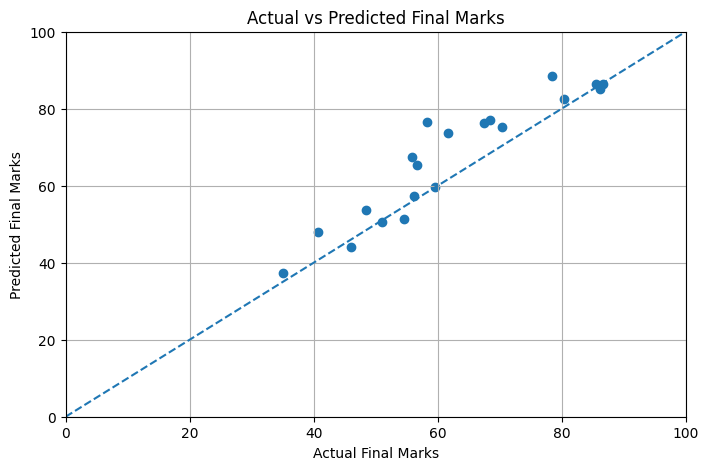

In [41]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test_large, predictions_large)

plt.plot([0, 100], [0, 100], linestyle="--")

plt.title("Actual vs Predicted Final Marks")
plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")

plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid(True)
plt.show()

## 32. Understanding Feature Coefficients

In this section, I will examine the Linear Regression coefficients to understand how study hours, attendance, and previous scores contribute to the model's predictions.

In [42]:
coefficients = pd.DataFrame({
    "Feature": X_train_large.columns,
    "Coefficient": model_large.coef_
})

print(coefficients.sort_values(
    by="Coefficient",
    ascending=False
).to_string(index=False))

print("\nIntercept:", round(model_large.intercept_, 2))

       Feature  Coefficient
   Study_Hours     5.697235
Previous_Score     0.435953
    Attendance     0.342251

Intercept: -6.57


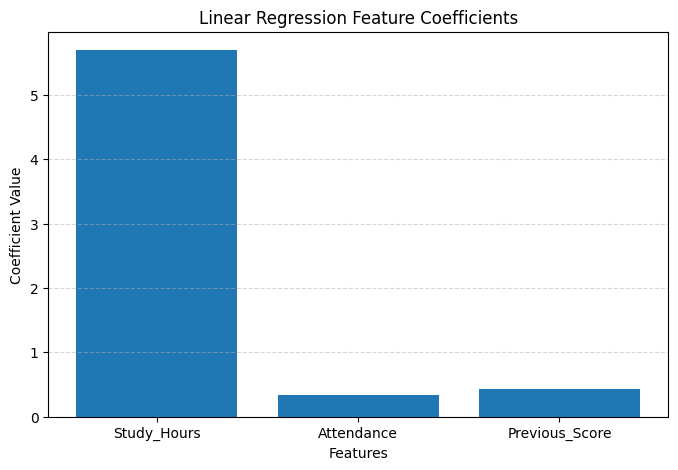

In [43]:
plt.figure(figsize=(8, 5))

plt.bar(
    coefficients["Feature"],
    coefficients["Coefficient"]
)

plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Features")
plt.ylabel("Coefficient Value")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [44]:
large_student_df.to_csv(
    "student_performance_data.csv",
    index=False
)

print("Dataset exported successfully!")

Dataset exported successfully!


In [45]:
from google.colab import files
files.download("student_performance_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Project Conclusion

In this project, I developed an AI-Powered Student Performance Prediction System using Python.

### Key Work Completed
- Created and analyzed a student performance dataset using Pandas and NumPy.
- Visualized student marks and relationships between study hours, attendance, previous scores, and final marks using Matplotlib.
- Trained a Linear Regression model using Scikit-learn.
- Evaluated the model using Mean Absolute Error (MAE) and R² score.
- Examined model coefficients to understand the relationship between input features and predicted marks.
- Created a function to predict marks for a new student.
- Exported the dataset to a CSV file.

### Model Evaluation
The model achieved a Mean Absolute Error of approximately 5.43 marks and an R² score of 0.757 on the test set.

**Limitation:** The dataset was synthetically generated for learning purposes. These results do not demonstrate accuracy on real student data.

### Future Improvements
- Train and test the model on a real, publicly available student performance dataset.
- Compare Linear Regression with other machine learning algorithms.
- Improve model evaluation and prediction reliability.
- Develop an interactive user interface for entering student details and viewing predictions.